In [2]:
# Data Exploration
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Pickle
import pickle

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn import neighbors
from sklearn.neural_network import MLPClassifier

# Onehotencoding
from sklearn.preprocessing import OneHotEncoder

# MinMaxScaler
from sklearn.preprocessing import MinMaxScaler

# train_test_split
from sklearn.model_selection import train_test_split

# metrics
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_score,
    confusion_matrix,
    recall_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
file_path = "F:\Desktop\Projects\Diabetes Prediction\Data\diabetes_prediction_dataset.csv"

# Read the CSV file
df = pd.read_csv(file_path)

# Display first 5 rows
print(df.head())

# Check dataset shape
print("Dataset Shape:", df.shape)
# Inspect Data
print("First 5 Rows of Dataset:")
print(df.head())

print("\nData Types and Non-Null Values:")
print(df.info())

print("\nSummary Statistics:")
print(df.describe(include='all'))

   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  
Dataset Shape: (100000, 9)
First 5 Rows of Dataset:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0     

In [10]:
df = df.head(3000)
df.to_csv("diabetes_prediction_dataset - Copy.csv", index=False)

In [11]:
df.shape
df.head()


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


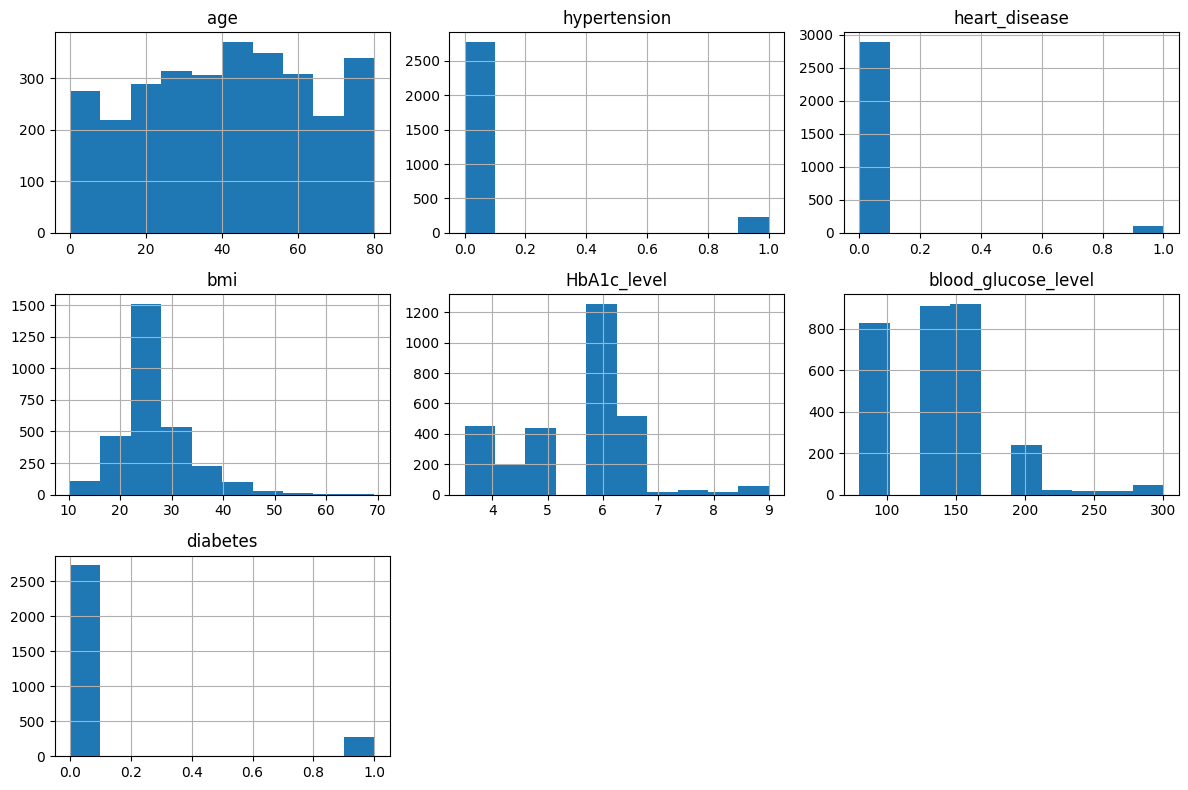

In [12]:
df.hist(bins=10, figsize=(12, 8))
plt.tight_layout()
plt.show()

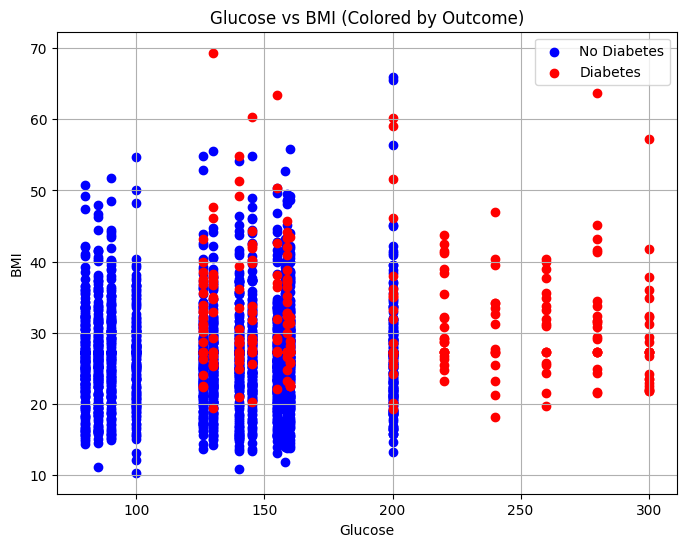

In [13]:
outcome_0 = df[df['diabetes'] == 0]
outcome_1 = df[df['diabetes'] == 1]
plt.figure(figsize=(8, 6))
plt.scatter(outcome_0['blood_glucose_level'], outcome_0['bmi'], color='blue', label='No Diabetes')
plt.scatter(outcome_1['blood_glucose_level'], outcome_1['bmi'], color='red', label='Diabetes')
plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.title('Glucose vs BMI (Colored by Outcome)')
plt.legend()
plt.grid(True)
plt.show()

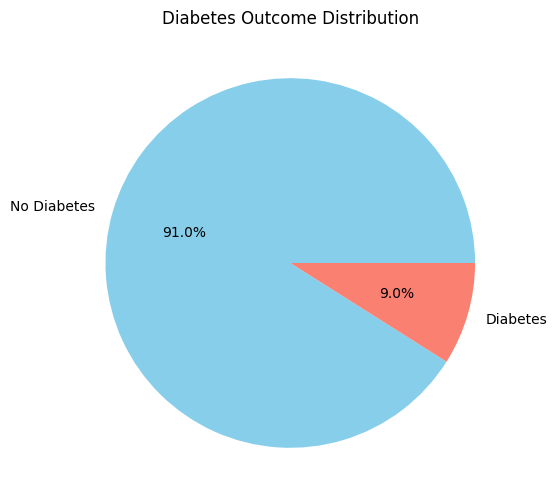

In [14]:
outcome_counts = df['diabetes'].value_counts()
labels = ['No Diabetes', 'Diabetes']
values = [outcome_counts[0], outcome_counts[1]]
plt.figure(figsize=(6, 6))
plt.pie(values, labels=labels, autopct='%1.1f%%', colors=['skyblue', 'salmon'])
plt.title('Diabetes Outcome Distribution')
plt.show()

In [15]:
y = df.diabetes
X = df.drop(["diabetes"], axis = 1)
X.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,Female,80.0,0,1,never,25.19,6.6,140
1,Female,54.0,0,0,No Info,27.32,6.6,80
2,Male,28.0,0,0,never,27.32,5.7,158
3,Female,36.0,0,0,current,23.45,5.0,155
4,Male,76.0,1,1,current,20.14,4.8,155


In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
display(X_train.shape)
display(X_test.shape)

display(y_train.shape)
display(y_test.shape)

(2400, 8)

(600, 8)

(2400,)

(600,)

Spliting numericals and categoricals

In [18]:
X_train_num = X_train.select_dtypes(include = np.number)
X_test_num  = X_test.select_dtypes(include = np.number)
X_train_cat = X_train.select_dtypes(include = object)
X_test_cat  = X_test.select_dtypes(include = object)


C:\Users\Team Knowhow\AppData\Local\Temp\ipykernel_30716\4289182529.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X_train_cat = X_train.select_dtypes(include = object)
C:\Users\Team Knowhow\AppData\Local\Temp\ipykernel_30716\4289182529.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/doc

In [19]:
encoder = OneHotEncoder(drop='first').fit(X_train_cat)
encoded_cat = encoder.transform(X_train_cat).toarray()
cols = encoder.get_feature_names_out(input_features=X_train_cat.columns)
X_train_encoded = pd.DataFrame(encoded_cat, columns=cols)
X_train_encoded

,gender_Male,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0
3,1.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...
2395,0.0,0.0,1.0,0.0,0.0,0.0
2396,1.0,1.0,0.0,0.0,0.0,0.0
2397,1.0,0.0,0.0,0.0,1.0,0.0
2398,0.0,0.0,0.0,0.0,0.0,0.0


In [20]:
encoded_test_cat = encoder.transform(X_test_cat).toarray()
X_test_encoded = pd.DataFrame(encoded_test_cat, columns=cols)
X_test_encoded

,gender_Male,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,1.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,1.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...
595,0.0,0.0,0.0,0.0,1.0,0.0
596,1.0,0.0,0.0,0.0,0.0,0.0
597,1.0,0.0,0.0,0.0,0.0,0.0
598,0.0,0.0,0.0,0.0,0.0,1.0


Scaling

In [21]:
transformer = MinMaxScaler().fit(X_train_num) # we will reuse this transformer for X_test later
X_train_scaled_arr = transformer.transform(X_train_num)
X_train_scaled = pd.DataFrame(X_train_scaled_arr, columns=X_train_num.columns)
X_train_scaled

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
0,0.799800,0.0,0.0,0.288133,0.400000,0.545455
1,0.199199,0.0,0.0,0.264771,0.545455,0.022727
2,0.024024,0.0,0.0,0.288133,0.400000,0.022727
3,0.587087,0.0,1.0,0.223633,0.000000,0.227273
4,0.737237,0.0,0.0,0.356188,0.454545,0.227273
...,...,...,...,...,...,...
2395,0.637137,0.0,0.0,0.468597,0.181818,0.363636
2396,0.724725,0.0,0.0,0.306416,0.236364,0.363636
2397,0.286787,0.0,0.0,0.288133,0.472727,0.022727
2398,0.837337,0.0,0.0,0.217031,0.418182,0.209091


In [22]:
X_test_scaled_arr = transformer.transform(X_test_num)
X_test_scaled = pd.DataFrame(X_test_scaled_arr, columns=X_test_num.columns)
X_test_scaled

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
0,0.699700,0.0,0.0,0.358388,0.472727,0.227273
1,0.461962,0.0,0.0,0.336888,0.236364,0.227273
2,0.787287,1.0,0.0,0.312680,0.090909,0.227273
3,0.211712,0.0,0.0,0.246826,0.400000,0.354545
4,0.299299,0.0,0.0,0.501608,0.236364,0.295455
...,...,...,...,...,...,...
595,1.000000,1.0,0.0,0.288133,0.600000,0.909091
596,0.224224,0.0,0.0,0.176909,0.563636,0.209091
597,0.124124,0.0,0.0,0.410022,0.418182,0.340909
598,0.624625,0.0,0.0,0.288133,0.236364,0.090909


Concatenating encoded and scaled columns

In [23]:

X_train_processed = pd.concat([X_train_encoded, X_train_scaled], axis = 1)
X_test_processed = pd.concat([X_test_encoded, X_test_scaled], axis = 1)

In [24]:
X_train_processed

,gender_Male,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
0,0.0,0.0,0.0,0.0,0.0,0.0,0.799800,0.0,0.0,0.288133,0.400000,0.545455
1,1.0,0.0,0.0,0.0,0.0,0.0,0.199199,0.0,0.0,0.264771,0.545455,0.022727
2,1.0,0.0,0.0,0.0,0.0,0.0,0.024024,0.0,0.0,0.288133,0.400000,0.022727
3,1.0,1.0,0.0,0.0,0.0,0.0,0.587087,0.0,1.0,0.223633,0.000000,0.227273
4,0.0,0.0,0.0,0.0,0.0,1.0,0.737237,0.0,0.0,0.356188,0.454545,0.227273
...,...,...,...,...,...,...,...,...,...,...,...,...
2395,0.0,0.0,1.0,0.0,0.0,0.0,0.637137,0.0,0.0,0.468597,0.181818,0.363636
2396,1.0,1.0,0.0,0.0,0.0,0.0,0.724725,0.0,0.0,0.306416,0.236364,0.363636
2397,1.0,0.0,0.0,0.0,1.0,0.0,0.286787,0.0,0.0,0.288133,0.472727,0.022727
2398,0.0,0.0,0.0,0.0,0.0,0.0,0.837337,0.0,0.0,0.217031,0.418182,0.209091


In [25]:
X_test_processed

,gender_Male,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
0,1.0,0.0,0.0,0.0,1.0,0.0,0.699700,0.0,0.0,0.358388,0.472727,0.227273
1,1.0,0.0,0.0,0.0,0.0,0.0,0.461962,0.0,0.0,0.336888,0.236364,0.227273
2,0.0,0.0,0.0,0.0,1.0,0.0,0.787287,1.0,0.0,0.312680,0.090909,0.227273
3,1.0,0.0,0.0,0.0,1.0,0.0,0.211712,0.0,0.0,0.246826,0.400000,0.354545
4,1.0,0.0,0.0,0.0,0.0,0.0,0.299299,0.0,0.0,0.501608,0.236364,0.295455
...,...,...,...,...,...,...,...,...,...,...,...,...
595,0.0,0.0,0.0,0.0,1.0,0.0,1.000000,1.0,0.0,0.288133,0.600000,0.909091
596,1.0,0.0,0.0,0.0,0.0,0.0,0.224224,0.0,0.0,0.176909,0.563636,0.209091
597,1.0,0.0,0.0,0.0,0.0,0.0,0.124124,0.0,0.0,0.410022,0.418182,0.340909
598,0.0,0.0,0.0,0.0,0.0,1.0,0.624625,0.0,0.0,0.288133,0.236364,0.090909


Logistic Regression

In [26]:
LR_model = LogisticRegression()
LR_model.fit(X_train_processed, y_train)
LR_model.score(X_test_processed, y_test)

0.96

In [27]:
y_test_pred = LR_model.predict(X_test_processed)

             Predicted Labels
             |   A    |     B
---------------------------------
True label A |  0.91 |    0.005
---------------------------------
           B |  0.04  |    0.051666666666666666


Text(0.5, 427.9555555555555, 'Predicted label')

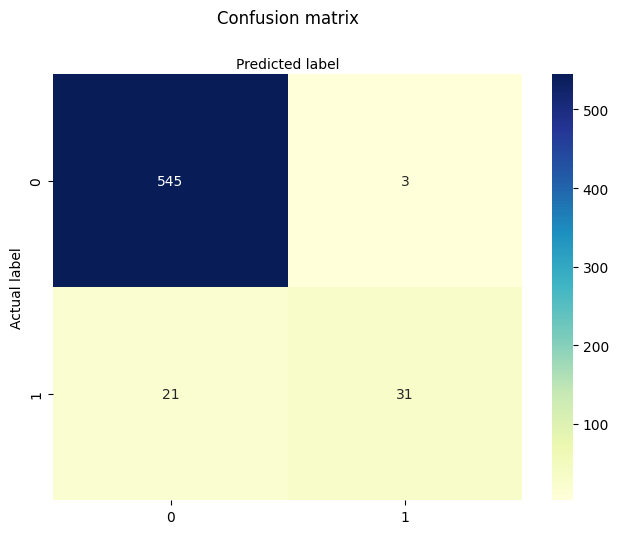

In [29]:
total = y_test.shape[0]

array = confusion_matrix(y_test, y_test_pred)
print('             Predicted Labels')
print('             |   A    |     B')
print('---------------------------------')
print('True label A | ',round((array[0][0]/total),2),'|   ', (array[0][1])/total)
print('---------------------------------')
print('           B | ',round((array[1][0]/total),2),' |   ', (array[1][1])/total)
class_names=['without diabetes', 'with diabetes'] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(array, annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

# Text(0.5,257.44,'Predicted label');

In [30]:
target_names = ['without diabetes', 'with diabetes']
print(classification_report(y_test, y_test_pred, target_names=target_names))

                  precision    recall  f1-score   support

without diabetes       0.96      0.99      0.98       548
   with diabetes       0.91      0.60      0.72        52

        accuracy                           0.96       600
       macro avg       0.94      0.80      0.85       600
    weighted avg       0.96      0.96      0.96       600



In [31]:
precision_score(y_test, y_test_pred)

0.9117647058823529

In [32]:
f1_score(y_test, y_test_pred)

0.7209302325581395

In [33]:
recall_score(y_test, y_test_pred)

0.5961538461538461

Correlation

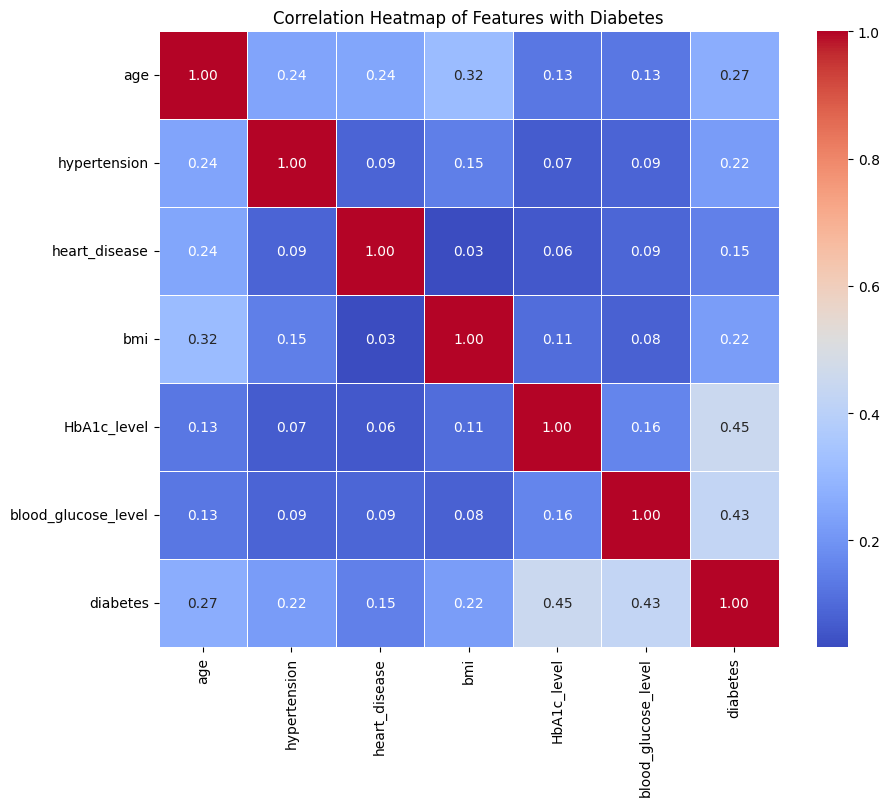

In [34]:
# Slide 4: Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Features with Diabetes')
plt.show()

HbA1c_Level and BloodGlucoseLevel distributions

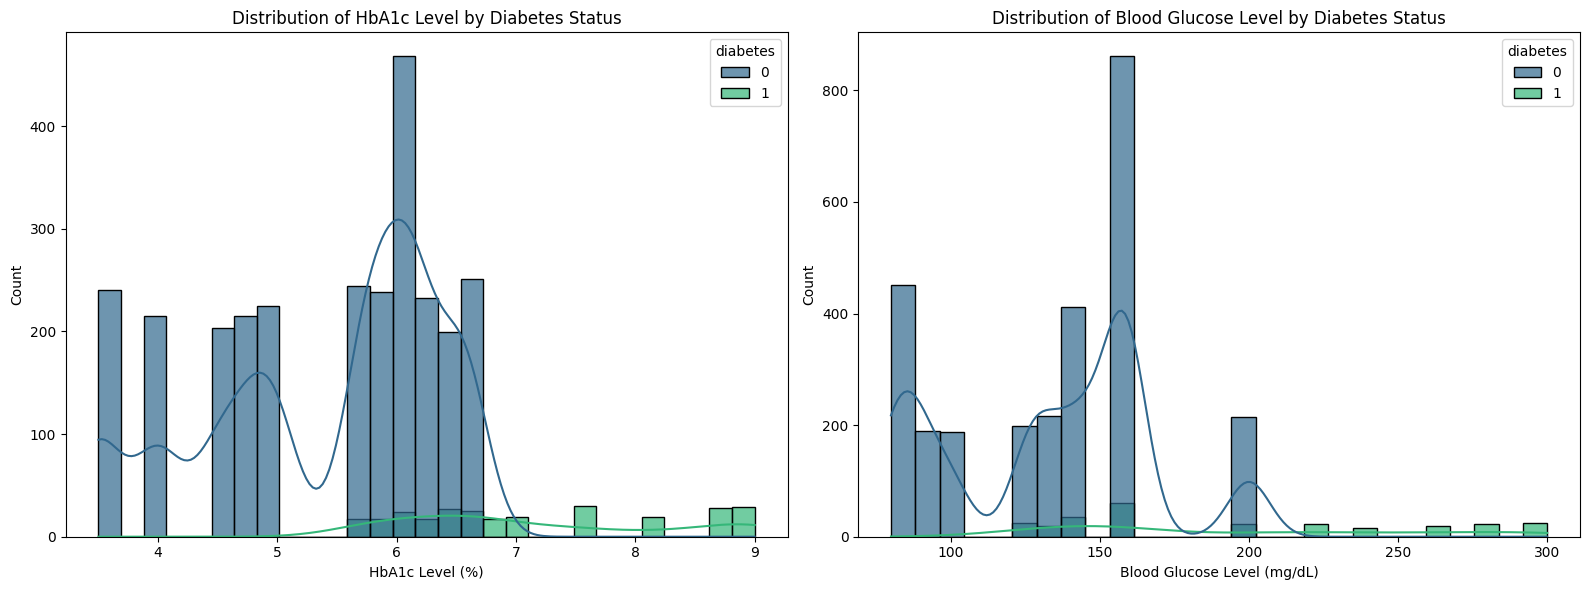

In [35]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(data=df, x='HbA1c_level', hue='diabetes', kde=True, ax=axes[0], palette='viridis', alpha=0.7)
axes[0].set_title('Distribution of HbA1c Level by Diabetes Status')
axes[0].set_xlabel('HbA1c Level (%)')
axes[0].set_ylabel('Count')

sns.histplot(data=df, x='blood_glucose_level', hue='diabetes', kde=True, ax=axes[1], palette='viridis', alpha=0.7)
axes[1].set_title('Distribution of Blood Glucose Level by Diabetes Status')
axes[1].set_xlabel('Blood Glucose Level (mg/dL)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()


# Slide 6: BMI and Age distributions

C:\Users\Team Knowhow\AppData\Local\Temp\ipykernel_30716\4197029089.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='diabetes', y='bmi', ax=axes[0], palette='pastel')


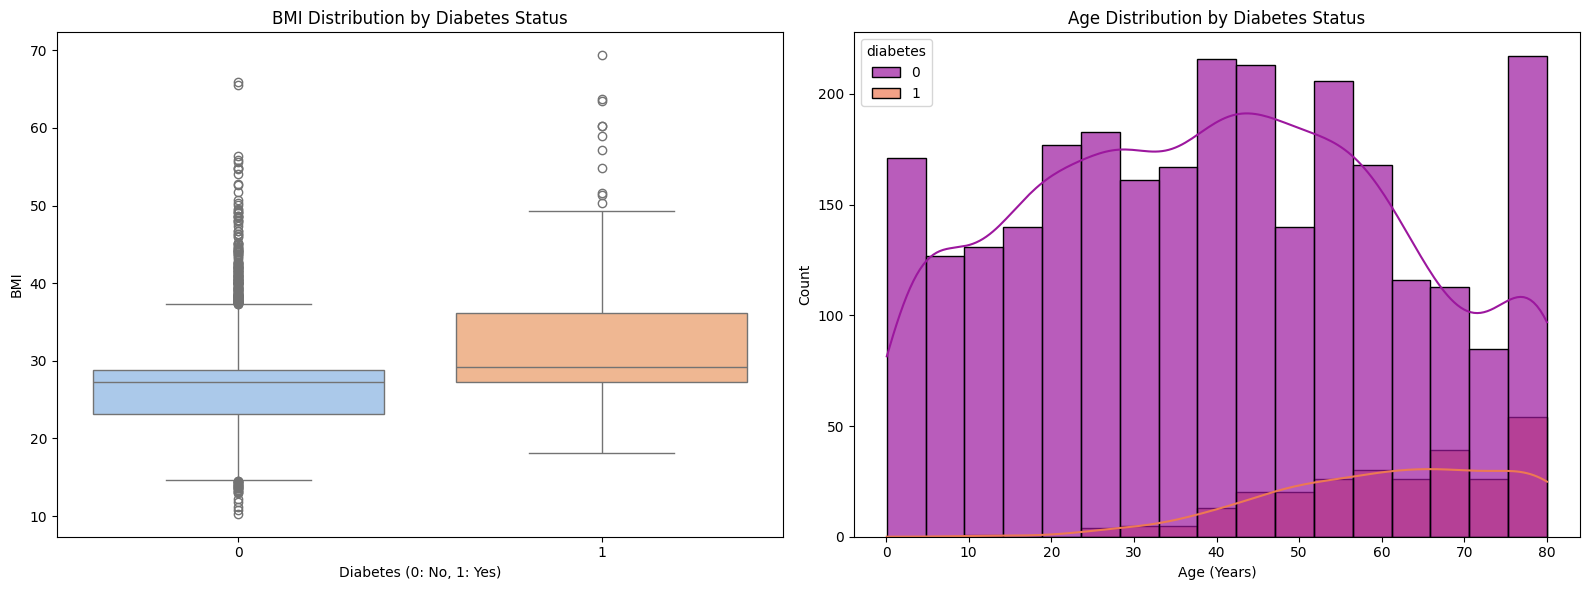

In [36]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df, x='diabetes', y='bmi', ax=axes[0], palette='pastel')
axes[0].set_title('BMI Distribution by Diabetes Status')
axes[0].set_xlabel('Diabetes (0: No, 1: Yes)')
axes[0].set_ylabel('BMI')

sns.histplot(data=df, x='age', hue='diabetes', kde=True, ax=axes[1], palette='plasma', alpha=0.7)
axes[1].set_title('Age Distribution by Diabetes Status')
axes[1].set_xlabel('Age (Years)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

C:\Users\Team Knowhow\AppData\Local\Temp\ipykernel_30716\353214024.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No Hypertension', 'Hypertension'])
C:\Users\Team Knowhow\AppData\Local\Temp\ipykernel_30716\353214024.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['No Heart Disease', 'Heart Disease'])


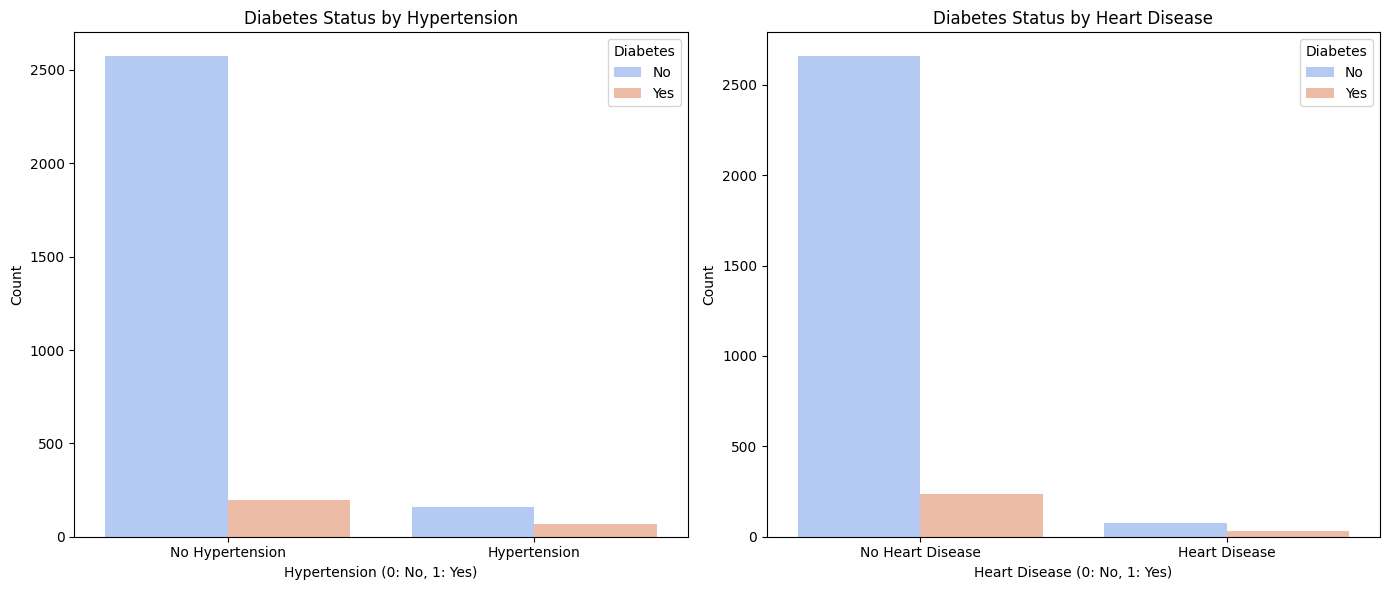

In [37]:
# Slide 7: Hypertension and Heart Disease vs. Diabetes
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Hypertension vs. Diabetes
sns.countplot(data=df, x='hypertension', hue='diabetes', ax=axes[0], palette='coolwarm')
axes[0].set_title('Diabetes Status by Hypertension')
axes[0].set_xlabel('Hypertension (0: No, 1: Yes)')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['No Hypertension', 'Hypertension'])
axes[0].legend(title='Diabetes', labels=['No', 'Yes'])

# Heart Disease vs. Diabetes
sns.countplot(data=df, x='heart_disease', hue='diabetes', ax=axes[1], palette='coolwarm')
axes[1].set_title('Diabetes Status by Heart Disease')
axes[1].set_xlabel('Heart Disease (0: No, 1: Yes)')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(['No Heart Disease', 'Heart Disease'])
axes[1].legend(title='Diabetes', labels=['No', 'Yes'])

plt.tight_layout()
plt.show()


Training set shape: (2400, 12)
Testing set shape: (600, 12)

Data scaling complete.

Training Logistic Regression...
Logistic Regression - Accuracy: 0.9550, Precision: 0.8462, Recall: 0.6111, F1-Score: 0.7097, ROC AUC: 0.9626

Training Random Forest...
Random Forest - Accuracy: 0.9667, Precision: 0.9474, Recall: 0.6667, F1-Score: 0.7826, ROC AUC: 0.9587

Training Gradient Boosting...
Gradient Boosting - Accuracy: 0.9650, Precision: 0.9231, Recall: 0.6667, F1-Score: 0.7742, ROC AUC: 0.9755

Model Performance Summary:
                     Accuracy Precision    Recall  F1-Score   ROC AUC
Model                                                                
Logistic Regression     0.955  0.846154  0.611111  0.709677  0.962556
Random Forest        0.966667  0.947368  0.666667  0.782609  0.958689
Gradient Boosting       0.965  0.923077  0.666667  0.774194  0.975478


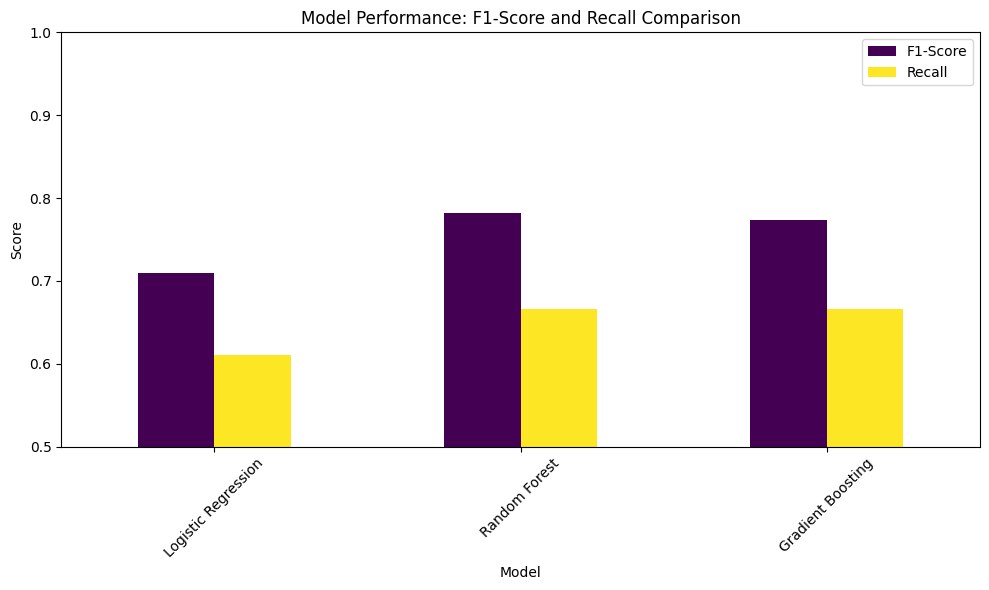

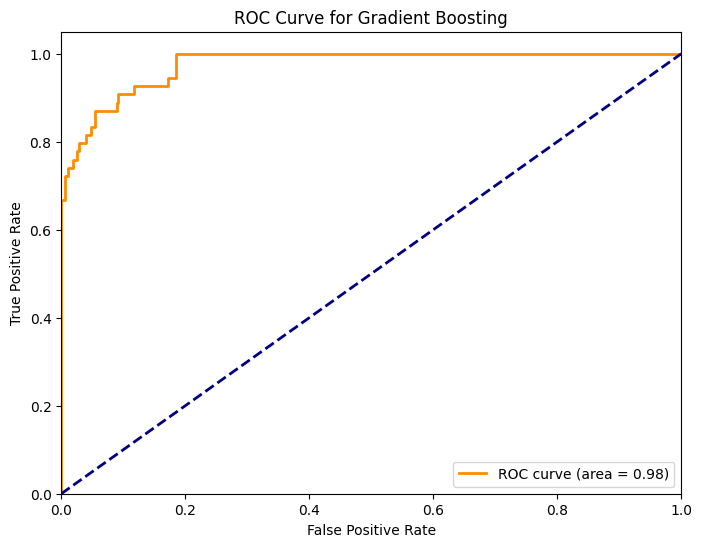

In [38]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier # Or LightGBM/XGBoost if installed
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
from sklearn.impute import SimpleImputer # Not strictly needed for this dataset, but good for general practice

# --- III. Data Analysis (Machine Learning Model Fitting) ---
df_processed = df.copy()
df_processed['gender'] = df_processed['gender'].map({'Male': 0, 'Female': 1}).fillna(0.5) # Handle 'Other' if it existed, or just map. 'Other' not in this specific dataset's unique values
df_processed['smoking_history'] = df_processed['smoking_history'].map({
    'never': 0, 'No Info': 0.5, 'current': 1, 'ever': 2, 'former': 3, 'not current': 4
}) # Assign numerical values. Order matters for some models, so careful. Or One-Hot Encode.
# For simplicity and given the dataset's nature, let's one-hot encode smoking_history for robust models.
df_processed = pd.get_dummies(df_processed, columns=['gender', 'smoking_history'], drop_first=True, dtype=int)
# Define features (X) and target (y)
X = df_processed.drop('diabetes', axis=1)
y = df_processed['diabetes']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# stratify=y ensures that the proportion of target variable is similar in both train and test sets

print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# Scale numerical features
# Identify numerical columns (excluding one-hot encoded and target)
numerical_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
scaler = StandardScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("\nData scaling complete.")

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, solver='liblinear'),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42, n_estimators=100)
}

results = {}
for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] # Probability for ROC AUC

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)

    results[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC AUC': roc_auc,
        'Model': model # Store the trained model to extract feature importance
    }
    print(f"{name} - Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1-Score: {f1:.4f}, ROC AUC: {roc_auc:.4f}")

# --- Slide 9: Model Training & Evaluation Visuals ---
metrics_df = pd.DataFrame(results).T[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC AUC']]
metrics_df.index.name = 'Model'

print("\nModel Performance Summary:")
print(metrics_df)

# Plotting F1-Score and Recall for comparison
fig, ax = plt.subplots(figsize=(10, 6))
metrics_df[['F1-Score', 'Recall']].plot(kind='bar', ax=ax, colormap='viridis')
ax.set_title('Model Performance: F1-Score and Recall Comparison')
ax.set_ylabel('Score')
ax.set_ylim(0.5, 1.0)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Plot ROC AUC Curve for the best model (e.g., Random Forest or Gradient Boosting)
best_model_name = metrics_df['ROC AUC'].idxmax()
best_model = results[best_model_name]['Model']
y_proba_best = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba_best)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {results[best_model_name]["ROC AUC"]:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve for {best_model_name}')
plt.legend(loc="lower right")
plt.show()



C:\Users\Team Knowhow\AppData\Local\Temp\ipykernel_30716\2530010494.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


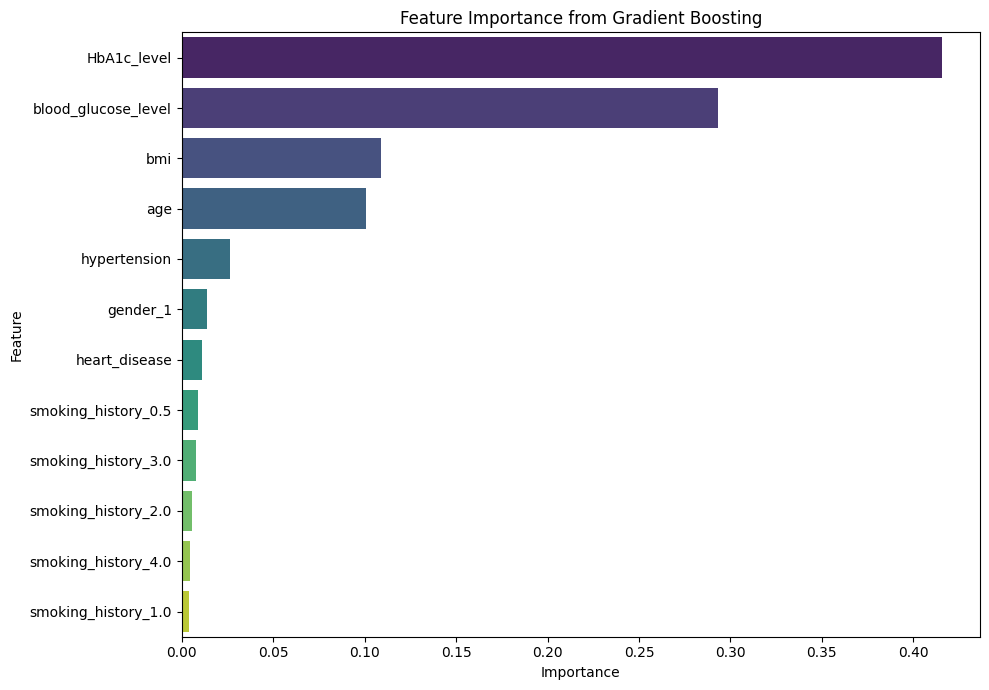

In [39]:
# --- Slide 10: Best Model Insights (Feature Importance) ---
# Assuming Random Forest or Gradient Boosting is the best or a strong performer
if 'Random Forest' in results:
    best_model_for_importance = results['Random Forest']['Model']
elif 'Gradient Boosting' in results:
    best_model_for_importance = results['Gradient Boosting']['Model']
else: # Fallback to Logistic Regression if others not available (less interpretable feature importance)
    best_model_for_importance = results['Logistic Regression']['Model']

# Get feature importances
if hasattr(best_model_for_importance, 'feature_importances_'):
    importances = best_model_for_importance.feature_importances_
    features = X.columns
    feature_importance_df = pd.DataFrame({'Feature': features, 'Importance': importances})
    feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

    plt.figure(figsize=(10, 7))
    sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
    plt.title(f'Feature Importance from {best_model_name}')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()
elif hasattr(best_model_for_importance, 'coef_'): # For Logistic Regression
    coefs = best_model_for_importance.coef_[0]
    features = X.columns
    coef_df = pd.DataFrame({'Feature': features, 'Coefficient': coefs})
    coef_df['Abs_Coefficient'] = np.abs(coef_df['Coefficient'])
    coef_df = coef_df.sort_values(by='Abs_Coefficient', ascending=False)

    plt.figure(figsize=(10, 7))
    sns.barplot(x='Coefficient', y='Feature', data=coef_df, palette='coolwarm')
    plt.title(f'Feature Coefficients from {best_model_name} (Magnitude of Impact)')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()